<a href="https://colab.research.google.com/github/heloisamariasl/DenverCoder1/blob/main/aula_dados.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Análise da base íris**

é um conjunto de dados clássico em estatística, ciência de dados e aprendizado de máquina que contém 150 amostras divididas igualmente entre três espécies de flores do gênero Iris.

In [15]:
# Gráficos
import seaborn as sns
import matplotlib.pyplot as plt


In [22]:
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)
df_iris = iris.frame
df_iris["species"] = df_iris["target"].map(dict(enumerate(iris.target_names)))
df_iris = df_iris.drop(columns="target")

df_iris.head(5)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


1. Como as espécies estão representadas na base?

Avaliando através do head, uma análise bem inicial conseguimos perceber que as flores são representadas pelo tamanho de suas sépalas e pétalas, além disso eles registram a mesma quantidade em cada espécie.

In [21]:
# Mostra a quantidade de registro por cada espécie
df_iris['species'].value_counts()



,count
species,
setosa,50
versicolor,50
virginica,50


2. Quais características das pétalas melhor diferenciam as espécies?

Por meio da média e do desvio padrão, percebemos que a característica petal length (cm) é a que mais evidencia essa diferença. O desvio padrão dentro de cada espécie é baixo, porém as médias são bem distantes entre si, como ocorre entre as espécies virginica e setosa, que apresentam uma grande diferença de tamanho. Além disso, a mediana ajuda a confirmar que essa diferença é realmente um padrão do grupo, e não resultado de algumas flores muito maiores que estariam distorcendo a média.

In [23]:
# Média de cada característica
df_iris.groupby('species').agg(['mean', 'std']) # Média de cada categaroria de tamanho da planta


sepal length (cm)           sepal width (cm)            \
                        mean       std             mean       std   
species                                                             
setosa                 5.006  0.352490            3.428  0.379064   
versicolor             5.936  0.516171            2.770  0.313798   
virginica              6.588  0.635880            2.974  0.322497   

           petal length (cm)           petal width (cm)            
                        mean       std             mean       std  
species                                                            
setosa                 1.462  0.173664            0.246  0.105386  
versicolor             4.260  0.469911            1.326  0.197753  
virginica              5.552  0.551895            2.026  0.274650

In [24]:
# Média e mediana da característica mais evidente
df_iris.groupby('species')['petal length (cm)'].agg(['mean', 'median', 'std'])


,mean,median,std
species,,,
setosa,1.462,1.50,0.173664
versicolor,4.260,4.35,0.469911
virginica,5.552,5.55,0.551895


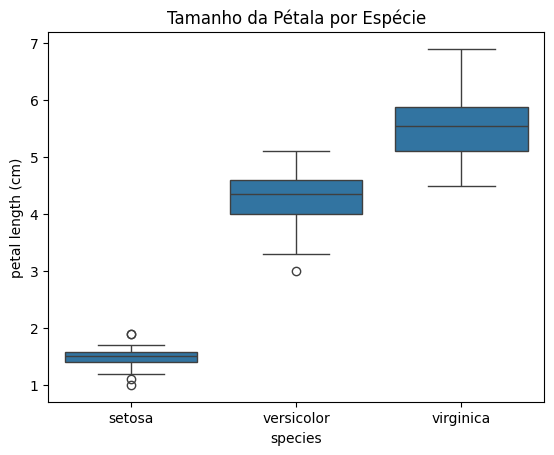

In [17]:
sns.boxplot(data=df_iris, x='species', y='petal length (cm)')
plt.title('Tamanho da Pétala por Espécie')
plt.show()


O gráfico Tamanho da Pétala por Espécie, expõem as tendência de cada uma delas em relação ao tamanho da pétala.

3. Existe uma relação entre o comprimento da sépala e o comprimento da pétala?


Sim, existe uma forte correlação positiva entre o comprimento da sépala e o comprimento da pétala, com um coeficiente entre todas as espécies de 0.87. Isso indica que, na maioria das vezes, quanto maior o comprimento da sépala, maior tende a ser o da pétala. Porém, ao dividir a análise por espécie percebemos que essa relação forte ocorre principalmente na virginica (0,86) e na versicolor (0,75). Já na setosa (0,27) a correlação é fraca, pois suas pétalas mantêm um tamanho pequeno e bastante constante, que cria uma maior independência da variação no tamanho da sépala.

In [14]:
# Correlação entre todas as espécies
correlacao = df_iris['sepal length (cm)'].corr(df_iris['petal length (cm)'])
print(f"Correlação geral: {correlacao:.2f}")
print()

# Correlação por espécie
# 1. Separando cada espécie em uma variável
setosa = df_iris[df_iris['species'] == 'setosa']
versicolor = df_iris[df_iris['species'] == 'versicolor']
virginica = df_iris[df_iris['species'] == 'virginica']

# 2. Calculando a correlação de cada uma do jeito simples
print("Correlação por espécie")
print("Setosa:", setosa['sepal length (cm)'].corr(setosa['petal length (cm)']))
print("Versicolor:", versicolor['sepal length (cm)'].corr(versicolor['petal length (cm)']))
print("Virginica:", virginica['sepal length (cm)'].corr(virginica['petal length (cm)']))


Correlação geral: 0.87

Correlação por espécie
Setosa: 0.26717575886875716
Versicolor: 0.754048958592016
Virginica: 0.8642247329355764


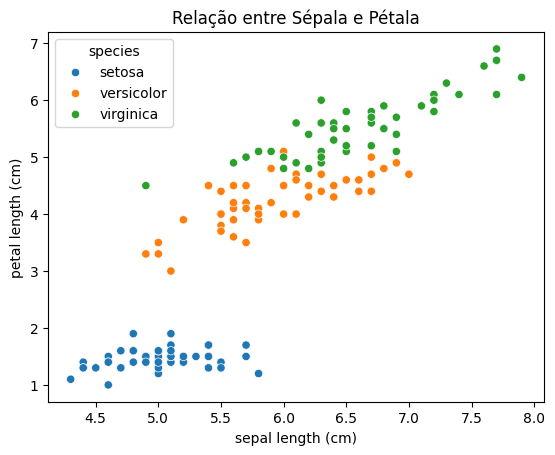

In [16]:
sns.scatterplot(data=df_iris, x='sepal length (cm)', y='petal length (cm)', hue='species')
plt.title('Relação entre Sépala e Pétala')
plt.show()


O gráfico acima expõem a correlação entre o tamanho da sépala e pétala que consegue ser observada tanto de modo geral, como em cada espécie de maneira específica.